# AdaBoost: learn from earlier mistakes

<a target="_blank" href="https://colab.research.google.com/github/changyaochen/MECE4520/blob/master/site/tree-based/07-adaboost.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

A fully grown decision tree can fit a complicated set of rules, but it can also be sensitive to the particular observations it sees. **AdaBoost (Adaptive Boosting)** takes a different route: it builds many decision stumps sequentially. A decision stump is a depth-1 tree with one split; we choose stumps here to make AdaBoost's mechanics easy to see, not because deeper base trees are prohibited. Each later tree pays more attention to the training observations that the earlier trees found difficult.

We will use the same gas-turbine classification task as the decision-tree, bagging, and random-forest lessons. Each row records one operating observation; the target is a binary label.

## What you will do

1. Start with equal weight on every training observation and fit one depth-one tree, called a *decision stump*.
2. Increase the weights of observations that stump misclassifies.
3. Repeat the process to build a sequence of stumps, then pool their weighted votes.
4. Evaluate the intermediate boosted models on the same test set using AUC of ROC.

Unlike bagging and random forests, AdaBoost does **not** make bootstrap datasets. Every stump sees the same training rows; only their weights change.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid", context="notebook")

## 1. Set up one training/test split

We keep one fixed split throughout the notebook. The test observations are never used to select a stump or update an observation weight.

In [2]:
FEATURES = ["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "TEY", "CDP"]
TARGET = "high_co"
RANDOM_STATE = 4520

data_candidates = [
    Path("../data/gas-turbine-course.csv"),
    Path("site/data/gas-turbine-course.csv"),
    Path("gas-turbine-course.csv"),
]
data_path = next((path for path in data_candidates if path.exists()), data_candidates[-1])
data = pd.read_csv(filepath_or_buffer=data_path)
model_data = data[FEATURES + [TARGET]].dropna().copy()

X_train, X_test, y_train, y_test = train_test_split(
    model_data[FEATURES],
    model_data[TARGET],
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=model_data[TARGET],
)

print(f"Training observations: {len(X_train):,}")
print(f"Test observations: {len(X_test):,}")
print(f"Positive-label fraction in training data: {y_train.mean():.3f}")

Training observations: 24,778
Test observations: 10,620
Positive-label fraction in training data: 0.388


## 2. Fit the first weighted stump

At the first round, each training observation has the same weight, $1/n$. A decision stump has just one split, so it is deliberately a weak individual model. AdaBoost will combine many of them.

For a stump $h_t$, its weighted error is

$$
e_t = \sum_{i=1}^{n} w_i^{(t)}\,\mathbb{1}\!\left[h_t(\mathbf{x}_i) \ne y_i\right].
$$

The stump receives the vote weight

$$
\alpha_t = \frac{1}{2}\log\!\left(\frac{1-e_t}{e_t}\right).
$$

A lower weighted error gives a larger $\alpha_t$, so a more reliable stump has more influence in the final vote.

In [3]:
def fit_adaboost_round(
    *,
    features: pd.DataFrame,
    labels: pd.Series,
    observation_weights: np.ndarray,
    random_state: int,
) -> tuple[DecisionTreeClassifier, np.ndarray, np.ndarray, float, float]:
    """Fit one AdaBoost stump and update the observation weights.

    Args:
        features: Training feature table.
        labels: Training binary labels.
        observation_weights: Normalized weights for the training observations.
        random_state: Seed used when fitting the decision stump.

    Returns:
        The fitted stump, its misclassified-training-sample mask, the normalized
        weights for the next round, its weighted error, and its vote weight.
    """
    stump = DecisionTreeClassifier(max_depth=1, random_state=random_state)
    stump.fit(
        X=features,
        y=labels,
        sample_weight=observation_weights,
    )

    training_prediction = stump.predict(features).astype(int)
    incorrect = training_prediction != labels.to_numpy(dtype=int)
    weighted_error = float(observation_weights[incorrect].sum())
    alpha = 0.5 * np.log((1 - weighted_error) / weighted_error)

    multiplier = np.where(incorrect, np.exp(alpha), np.exp(-alpha))
    next_weights = observation_weights * multiplier
    next_weights = next_weights / next_weights.sum()

    return stump, incorrect, next_weights, weighted_error, float(alpha)

In [4]:
initial_weights = np.full(shape=len(X_train), fill_value=1 / len(X_train))
first_stump, first_incorrect, second_weights, first_error, first_alpha = fit_adaboost_round(
    features=X_train,
    labels=y_train,
    observation_weights=initial_weights,
    random_state=RANDOM_STATE,
)

root_feature = FEATURES[first_stump.tree_.feature[0]]
root_threshold = first_stump.tree_.threshold[0]
print(f"First stump rule: {root_feature} ≤ {root_threshold:.3f}")
print(f"Weighted error: {first_error:.3f}")
print(f"Vote weight α₁: {first_alpha:.3f}")

First stump rule: TIT ≤ 1076.950
Weighted error: 0.154
Vote weight α₁: 0.852


### What each fitted stump gives us

At boosting round $t$, AdaBoost keeps track of a few different objects. The distinction between a single number and one value per training observation is important:

| Object | Shape / constraint | Intuition | First-round example |
|---|---|---|---|
| Stump predictions $h_t(\mathbf{x}_1), \ldots, h_t(\mathbf{x}_n)$ | Vector of length $n$; entries are in $\{0,1\}$ | They identify the samples the stump classifies correctly and those it misclassifies. | $24{,}778$ predicted labels |
| Weighted error $e_t$ | One scalar, $0 \le e_t \le 1$ | The error made by the current stump, weighted by the current observation weights. Samples misclassified by earlier stumps tend to count more. | $e_1 = 0.154$ |
| Vote weight $\alpha_t$ | One scalar; positive when $e_t < 0.5$ | How valuable this base model is to the ensemble: a more reliable stump receives a larger vote in the final prediction. | $\alpha_1 = 0.852$ |
| Current observation weights $\mathbf{w}^{(t)}$ | Vector of length $n$; each entry is nonnegative and the entries sum to $1$ | One importance value per training observation; these weights are used to fit the current stump. | Initially, every entry is $1/24{,}778 \approx 0.0000404$ |
| Updated observation weights $\mathbf{w}^{(t+1)}$ | Vector of length $n$; each entry is nonnegative and the entries sum to $1$ | After we increase the weights of misclassified samples and normalize, this vector tells the next stump where to focus. | Misclassified samples: $0.000131$ each; correctly classified samples: $0.0000239$ each |

Let’s now construct that updated weight vector.


## 3. Increase the weight of misclassified samples

After fitting stump $t$, its misclassified samples should matter more to the next stump. **The key idea of AdaBoost’s update is to rebalance attention:** after reweighting, the samples misclassified by the current stump collectively carry half of the total weight, and the samples it classified correctly carry the other half.

Before the update, those two groups carry total weights $e_t$ and $1-e_t$, respectively. The $\alpha_t$ selected in Section 2 satisfies

$$
e_t\exp(\alpha_t) = (1-e_t)\exp(-\alpha_t),
$$

so multiplying the misclassified and correctly classified samples by the following factors gives both groups the same total weight before normalization. After normalization, each group has weight $0.5$. The two groups are defined by the *current* stump, so they can change at the next round.

We keep the labels and stump predictions as $y_i, h_t(\mathbf{x}_i) \in \{0,1\}$. First, create one multiplier for each training observation:

$$
m_i^{(t)} = \exp(\alpha_t) \qquad \text{if } h_t(\mathbf{x}_i) \ne y_i.
$$

$$
m_i^{(t)} = \exp(-\alpha_t) \qquad \text{if } h_t(\mathbf{x}_i) = y_i.
$$

Then multiply the current weight by that multiplier and renormalize all weights to sum to one:

$$
w_i^{(t+1)} = \frac{w_i^{(t)}m_i^{(t)}}{\sum_{j=1}^{n} w_j^{(t)}m_j^{(t)}}.
$$

This is exactly what the code does with `np.where(...)`: a mistake receives $\exp(\alpha_t)$, a correct prediction receives $\exp(-\alpha_t)$, and the final division by the sum normalizes the new weights.

For the first stump, the following table compares the total training weight carried by correctly classified and misclassified samples.

In [5]:
weight_shift = pd.DataFrame(
    {
        "Before the update": [
            initial_weights[~first_incorrect].sum(),
            initial_weights[first_incorrect].sum(),
        ],
        "After the update": [
            second_weights[~first_incorrect].sum(),
            second_weights[first_incorrect].sum(),
        ],
    },
    index=["Correctly classified samples", "Misclassified samples"],
)
weight_shift.style.format("{:.1%}")

,Before the update,After the update
Correctly classified samples,84.6%,50.0%
Misclassified samples,15.4%,50.0%


The first stump misclassified only a fraction of the training samples, but after the update those same samples carry half of the total weight. The next stump is therefore pushed toward a complementary rule.

## 4. Repeat the weighted fitting process

Now let’s repeat Sections 2 and 3 for twelve rounds. At every round, we fit a stump using the current observation weights, compute its weighted error and vote weight, then update the weights for the next stump. The fitted stumps and their vote weights together form the trained AdaBoost model.

We calculate held-out AUC after each round only to inspect how the progressively larger ensemble performs.

In [6]:
def fit_adaboost(
    *,
    training_features: pd.DataFrame,
    training_labels: pd.Series,
    test_features: pd.DataFrame,
    test_labels: pd.Series,
    n_rounds: int,
    random_state: int,
) -> tuple[list[DecisionTreeClassifier], pd.DataFrame, np.ndarray]:
    """Fit sequential AdaBoost stumps and record held-out AUC.

    Args:
        training_features: Feature table used to fit every stump.
        training_labels: Binary labels for the training observations.
        test_features: Held-out feature table used only for evaluation.
        test_labels: Held-out binary labels.
        n_rounds: Number of sequential stumps to fit.
        random_state: Seed for reproducible stump fitting.

    Returns:
        The fitted stumps, a round-by-round summary, and test-set scores
        from the final weighted ensemble.
    """
    weights = np.full(shape=len(training_features), fill_value=1 / len(training_features))
    ensemble_margin = np.zeros(shape=len(test_features))
    alpha_total = 0.0
    stumps = []
    records = []

    for round_index in range(n_rounds):
        stump, incorrect, weights, weighted_error, alpha = fit_adaboost_round(
            features=training_features,
            labels=training_labels,
            observation_weights=weights,
            random_state=random_state,
        )
        test_prediction = stump.predict(test_features).astype(int)
        ensemble_margin += alpha * (2 * test_prediction - 1)
        alpha_total += alpha
        positive_vote = (ensemble_margin / alpha_total + 1) / 2

        stumps.append(stump)
        records.append(
            {
                "Round": round_index + 1,
                "Feature": FEATURES[stump.tree_.feature[0]],
                "Weighted error": weighted_error,
                "Vote weight α": alpha,
                "Held-out AUC": roc_auc_score(test_labels, positive_vote),
            }
        )

    return stumps, pd.DataFrame(records), positive_vote


stumps, round_summary, final_test_score = fit_adaboost(
    training_features=X_train,
    training_labels=y_train,
    test_features=X_test,
    test_labels=y_test,
    n_rounds=12,
    random_state=RANDOM_STATE,
)
round_summary.style.format(
    {
        "Weighted error": "{:.3f}",
        "Vote weight α": "{:.3f}",
        "Held-out AUC": "{:.3f}",
    }
)

,Round,Feature,Weighted error,Vote weight α,Held-out AUC
0,1,TIT,0.154,0.852,0.818
1,2,TIT,0.458,0.085,0.829
2,3,TIT,0.426,0.150,0.829
3,4,TIT,0.438,0.125,0.829
4,5,AFDP,0.401,0.200,0.852
5,6,TEY,0.439,0.122,0.853
6,7,TIT,0.470,0.060,0.853
7,8,TIT,0.469,0.063,0.853
8,9,TEY,0.472,0.057,0.853
9,10,TEY,0.478,0.044,0.853


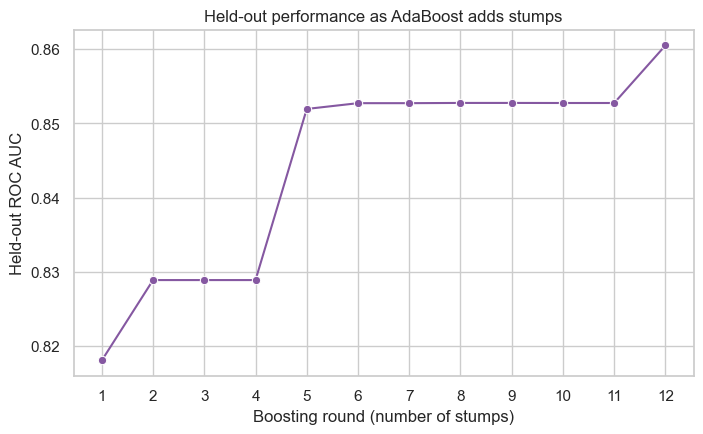

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.lineplot(
    data=round_summary,
    x="Round",
    y="Held-out AUC",
    marker="o",
    color="#8558a1",
    ax=ax,
)
ax.set(
    title="Held-out performance as AdaBoost adds stumps",
    xlabel="Boosting round (number of stumps)",
    ylabel="Held-out ROC AUC",
)
ax.set_xticks(round_summary["Round"])
plt.show()

## 5. Use the trained model for prediction

For a new feature vector $\mathbf{x}$, each trained stump votes for label 0 or 1. The ensemble combines those votes using the $\alpha_t$ values rather than giving every stump the same influence:

$$
s_T(\mathbf{x}) = \frac{\sum_{t=1}^{T} \alpha_t h_t(\mathbf{x})}{\sum_{t=1}^{T} \alpha_t}.
$$

This score ranks observations from more negative-like to more positive-like. It is useful for AUC of ROC, but unlike a logistic-regression output, it is not automatically a calibrated probability. Let’s inspect the weighted vote for one held-out operating observation.

In [8]:
EXAMPLE_TEST_POSITION = 4520
example_features = X_test.iloc[[EXAMPLE_TEST_POSITION]]
example_votes = np.array(
    [stump.predict(example_features)[0] for stump in stumps],
    dtype=int,
)
vote_weights = round_summary["Vote weight α"].to_numpy()
pooled_vote = np.average(example_votes, weights=vote_weights)

vote_table = pd.DataFrame(
    {
        "Stump": np.arange(1, len(stumps) + 1),
        "Vote": example_votes,
        "Vote weight α": vote_weights,
    }
)
display(vote_table.style.format({"Vote weight α": "{:.3f}"}))
print(f"Ground-truth label: {y_test.iloc[EXAMPLE_TEST_POSITION]}")
print(f"Pooled positive vote: {pooled_vote:.3f}")

,Stump,Vote,Vote weight α
0,1,1,0.852
1,2,0,0.085
2,3,1,0.150
3,4,0,0.125
4,5,1,0.200
5,6,0,0.122
6,7,1,0.060
7,8,0,0.063
8,9,1,0.057
9,10,0,0.044


Ground-truth label: 1
Pooled positive vote: 0.765


## 6. What AdaBoost changes

- **Bagging / random forests:** independent trees are averaged. Their diversity comes from bootstrap samples and, for random forests, random feature candidates.
- **AdaBoost:** trees are fitted one after another. Their diversity comes from repeatedly changing which training observations receive the most weight.
- The main hyperparameters here are the number of stumps, their depth, and a learning rate that can shrink each stump's vote weight.
- AdaBoost's emphasis on hard cases can be useful, but it can also make the model sensitive to mislabeled observations or outliers. Gradient boosting will keep the sequential idea while generalizing it to directly reduce a chosen loss function.

[Open the AdaBoost explorer](07-adaboost-explorer.qmd)  
[Return to Tree-based models](index.qmd)